# Epigenetic clocks in three schizophrenia cohorts

Displays the results of `python -m agetarget clocks` (one folder per cohort in `results/clocks/`) and `python -m agetarget pool` (`results/clocks/pooled/`). Nothing is computed here. The write-up is `docs/1-clocks.md`.

In [1]:
import json

import pandas as pd
from IPython.display import Image, Markdown, display

from agetarget import config as cfg

pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

R = cfg.CLOCK_RESULTS
COHORTS = list(cfg.COHORTS)
samples = {g: pd.read_csv(R / g / "samples.csv", index_col=0) for g in COHORTS}
summary = {g: json.loads((R / g / "summary.json").read_text()) for g in COHORTS}

## 1. Cohorts and QC

Every sample GEO lists, by QC status: samples without a usable age are not analysed at all; sex mismatches and manual exclusions stay in the "all samples" analysis but not in the QC-passed one.

In [2]:
pd.concat({g: s.groupby("group")["status"].value_counts().unstack(fill_value=0) for g, s in samples.items()})

status                  QC-passed  manual exclusion  sex mismatch  no usable age
         group                                                                  
GSE41169 control               31               0.0           2.0            NaN
         schizophrenia         61               1.0           0.0            NaN
GSE80417 control              304               NaN           NaN           18.0
         schizophrenia        332               NaN           NaN           21.0
GSE84727 control              405               NaN           NaN           28.0
         schizophrenia        260               NaN           NaN          154.0

In [3]:
rows = {}
for g, s in samples.items():
    for grp, d in s[s.status != "no usable age"].groupby("group"):
        rows[(g, grp)] = {"n": len(d), "median age": d.age.median(), "male (%)": round(100 * (d.sex == "Male").mean()),
                          "smoking score": d.smoking.mean()}
display(pd.DataFrame(rows).T)

checks = pd.DataFrame({g: {
    "CpGs": f"{s['cpgs']:,}",
    "implausible ages": ", ".join(f"{k} ({v:g})" for k, v in s["implausible_ages"].items()) or "none",
    "sex check": (f"{len(s['sex_check']['mismatches'])} mismatches" if s["sex_check"]["ran"]
                  else "not possible (X {X:.0%}, Y {Y:.0%} of probes)".format(**s["sex_check"]["probe_coverage"])),
    "manual exclusions": ", ".join(s["manual_exclusions"]) or "none",
    "QC-passed": s["n_qc_passed"],
} for g, s in summary.items()}).T
checks

n  median age  male (%)  smoking score
GSE41169 control         33.0        27.0      64.0          3.144
         schizophrenia   62.0        31.5      74.0          4.390
GSE80417 control        304.0        31.0      44.0          3.611
         schizophrenia  332.0        42.0      73.0          4.906
GSE84727 control        405.0        46.4      75.0          3.687
         schizophrenia  260.0        43.4      68.0          4.455

,CpGs,implausible ages,sex check,manual exclusions,QC-passed
GSE41169,"485,577",none,2 mismatches,GSM1009696,92
GSE80417,"483,636","GSM2126406 (891), GSM2126750 (883)",0 mismatches,none,636
GSE84727,"420,374",none,"not possible (X 0%, Y 0% of probes)",none,665


## 2. Agreement with chronological age

Pearson r and mean absolute error (years) per clock. DunedinPACE is a rate, so it has no error in years and is not expected to track age.

In [4]:
metrics = pd.concat({g: pd.read_csv(R / g / "clock_metrics.csv", index_col=0) for g in COHORTS}, axis=1)
metrics.loc[cfg.CLOCK_ORDER[::-1], (slice(None), ["pearson_r", "mae_years"])].round(2)

GSE41169            GSE80417            GSE84727          
            pearson_r mae_years pearson_r mae_years pearson_r mae_years
clock                                                                  
GrimAge2         0.85     14.59      0.91     16.16      0.90     14.66
DunedinPACE      0.50       NaN      0.39       NaN      0.28       NaN
CausAge          0.92      6.76      0.94      4.69      0.95      6.12
PhenoAge         0.91      5.57      0.91      5.13      0.91      4.36
Hannum           0.93      3.05      0.95      7.56      0.95      7.77
Horvath          0.93      2.95      0.93      4.81      0.94      5.04

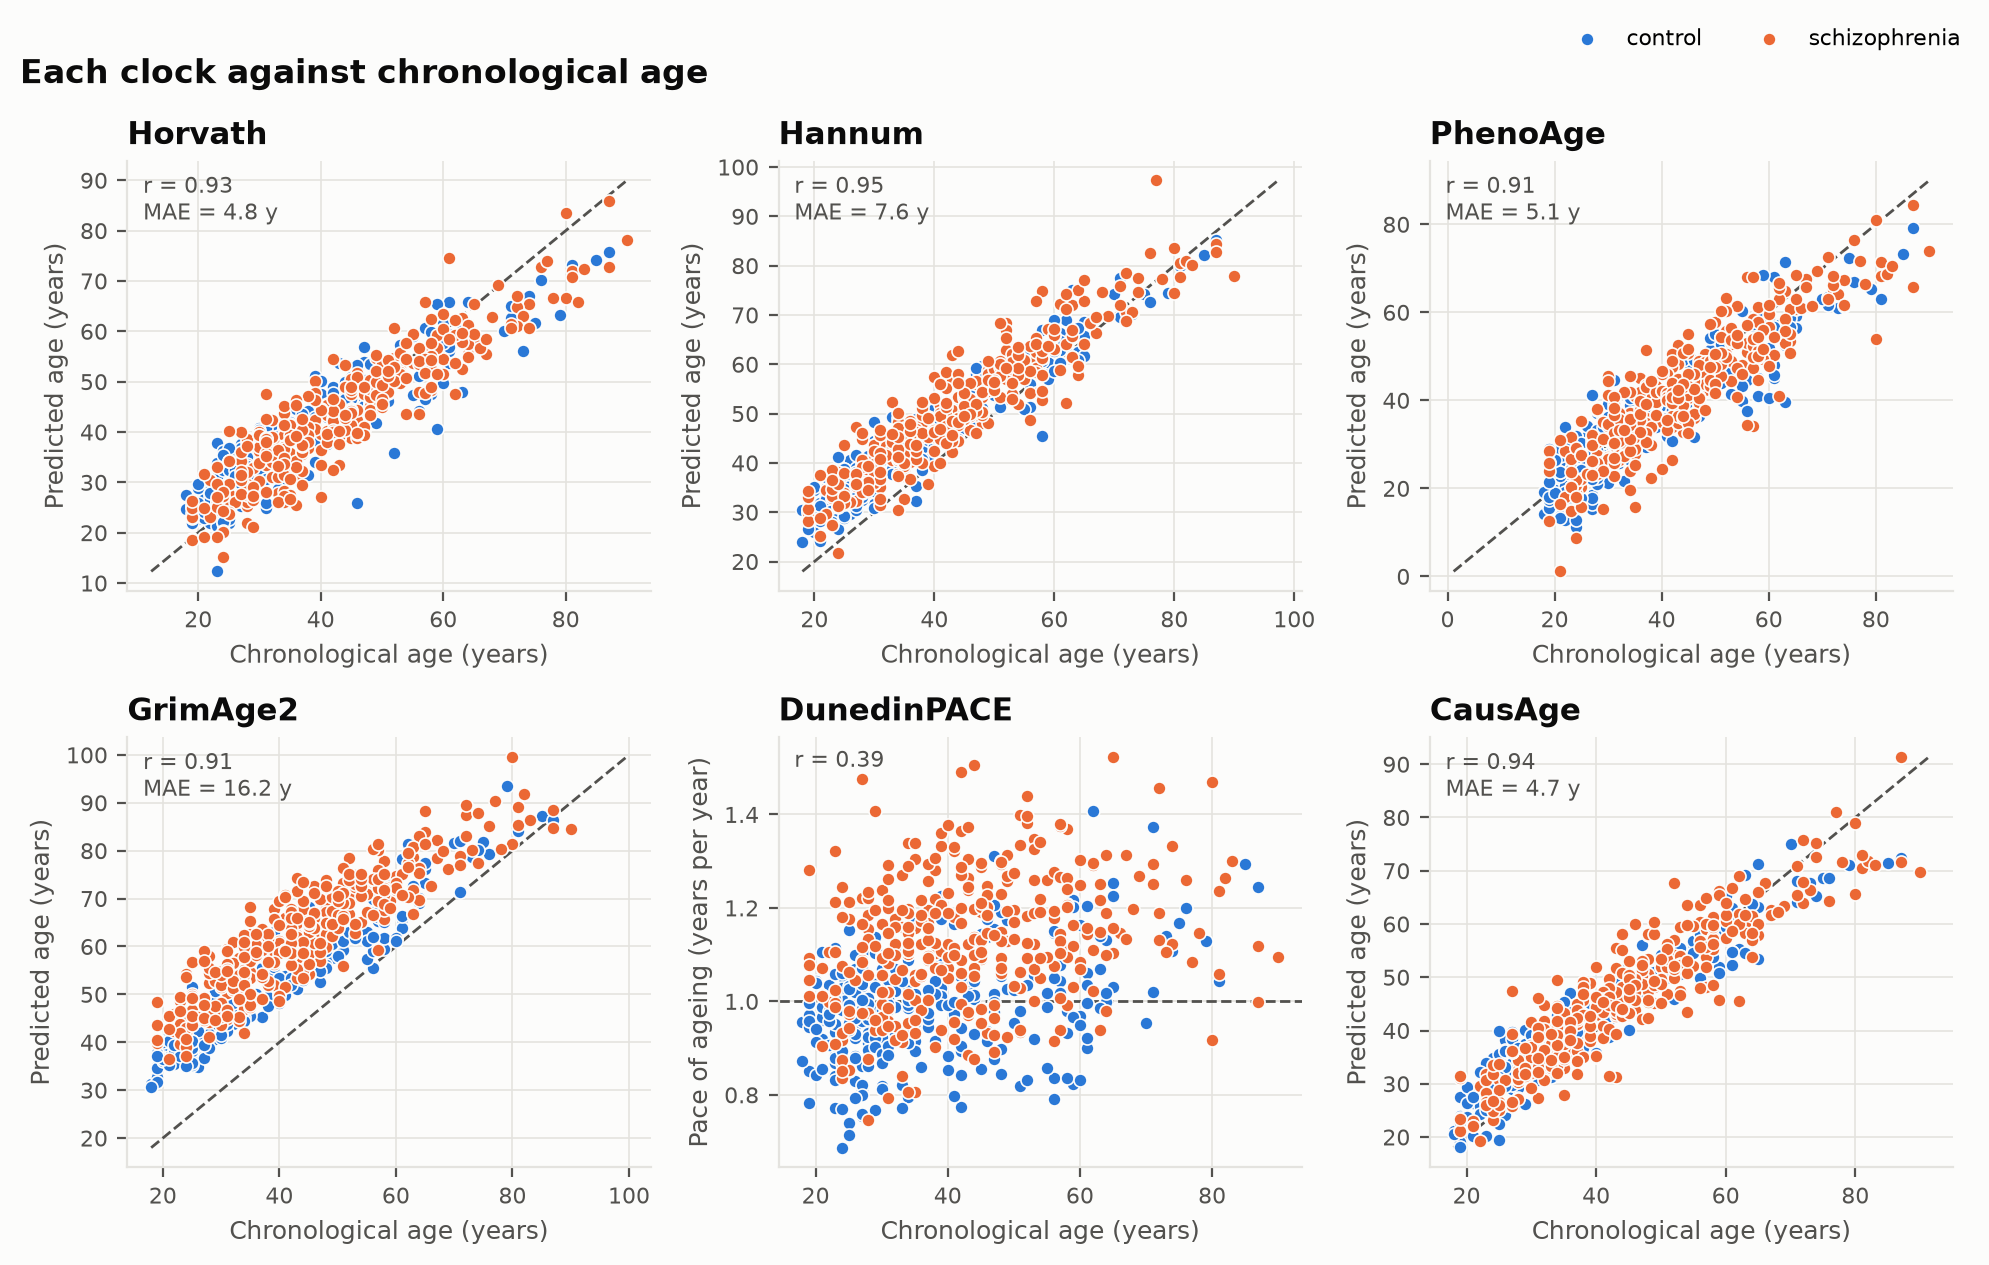

In [5]:
display(Image(filename=R / "GSE80417" / "predicted_vs_age.png", width=900))

## 3. Schizophrenia vs control

Case minus control in age deviation (the residual of each clock on chronological age), in years or, for DunedinPACE, biological years per calendar year. QC-passed samples, three nested covariate models.

In [6]:
adjusted = pd.concat([pd.read_csv(R / g / "case_control_adjusted.csv").assign(cohort=g) for g in COHORTS])
qc = adjusted[adjusted.samples == "QC-passed"]
diff = qc.pivot_table(index="clock", columns=["model", "cohort"], values="diff_adjusted")
p = qc.pivot_table(index="clock", columns=["model", "cohort"], values="p_adjusted")
order = cfg.CLOCK_ORDER[::-1]
print("Difference, schizophrenia minus control:")
display(diff.loc[order, list(cfg.COVARIATE_MODELS)].round(3))
print("p-value:")
display(p.loc[order, list(cfg.COVARIATE_MODELS)].map(lambda v: f"{v:.2g}"))

Difference, schizophrenia minus control:


model            sex                   sex+smoking                   sex+smoking+cells                  
cohort      GSE41169 GSE80417 GSE84727    GSE41169 GSE80417 GSE84727          GSE41169 GSE80417 GSE84727
clock                                                                                                   
GrimAge2       4.552    5.623    4.158      -1.004    0.630    1.078            -0.670    0.237    0.552
DunedinPACE    0.077    0.122    0.098      -0.002    0.044    0.054             0.004    0.034    0.038
CausAge       -1.199    0.324    0.873      -0.567    0.030    0.802            -0.451   -0.294    0.541
PhenoAge      -0.233    1.258    1.482      -0.921    0.774    0.836            -0.553    0.005    0.205
Hannum        -0.988    0.319    0.749      -0.720    0.517    0.930            -0.525   -0.142    0.278
Horvath       -1.420   -0.815   -0.222      -0.844   -0.222   -0.035            -0.688   -0.136   -0.039

p-value:


model            sex                   sex+smoking                   sex+smoking+cells                  
cohort      GSE41169 GSE80417 GSE84727    GSE41169 GSE80417 GSE84727          GSE41169 GSE80417 GSE84727
clock                                                                                                   
GrimAge2     0.00044  1.9e-42  4.1e-32        0.13     0.03  1.5e-06              0.29      0.4    0.012
DunedinPACE   0.0013    9e-30  1.8e-27        0.92    6e-05  4.1e-10              0.82   0.0016  1.5e-05
CausAge         0.17     0.36   0.0013        0.56     0.94   0.0071              0.65      0.5     0.08
PhenoAge        0.82     0.01  0.00017        0.42     0.19     0.05               0.6     0.99     0.64
Hannum          0.24     0.34   0.0031        0.45      0.2  0.00079              0.52     0.72     0.31
Horvath         0.08    0.037     0.44        0.35     0.64     0.91              0.46     0.78     0.91

**GSE41169**

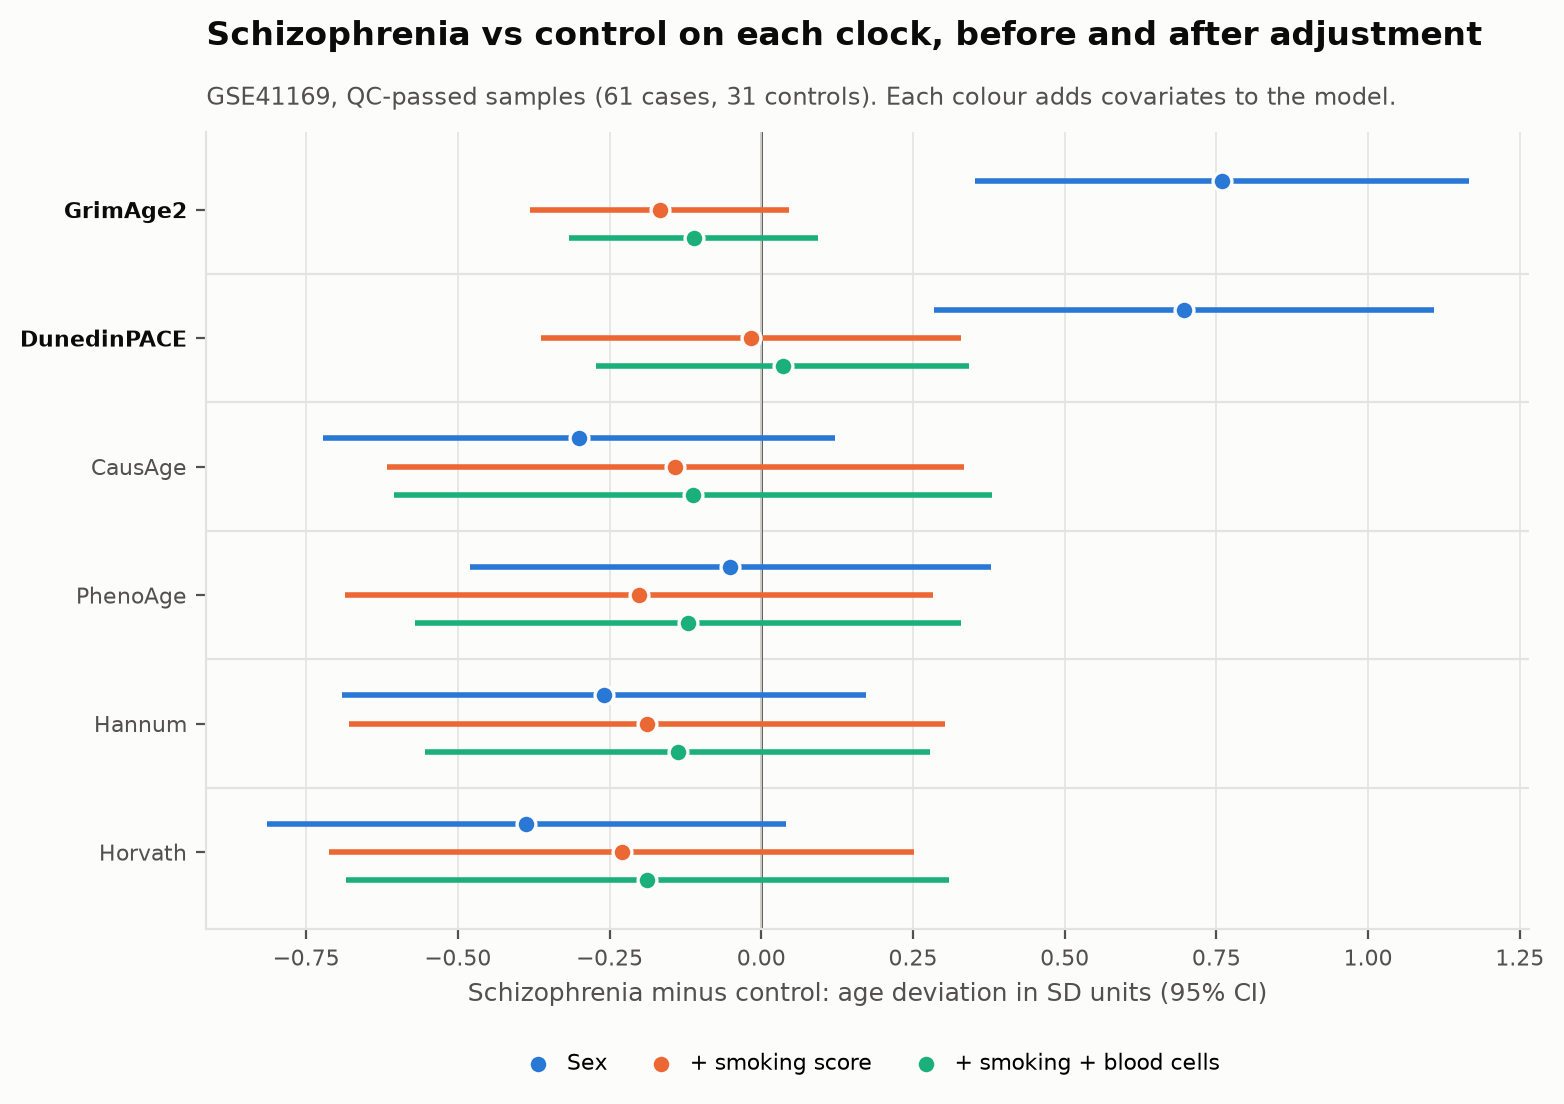

**GSE80417**

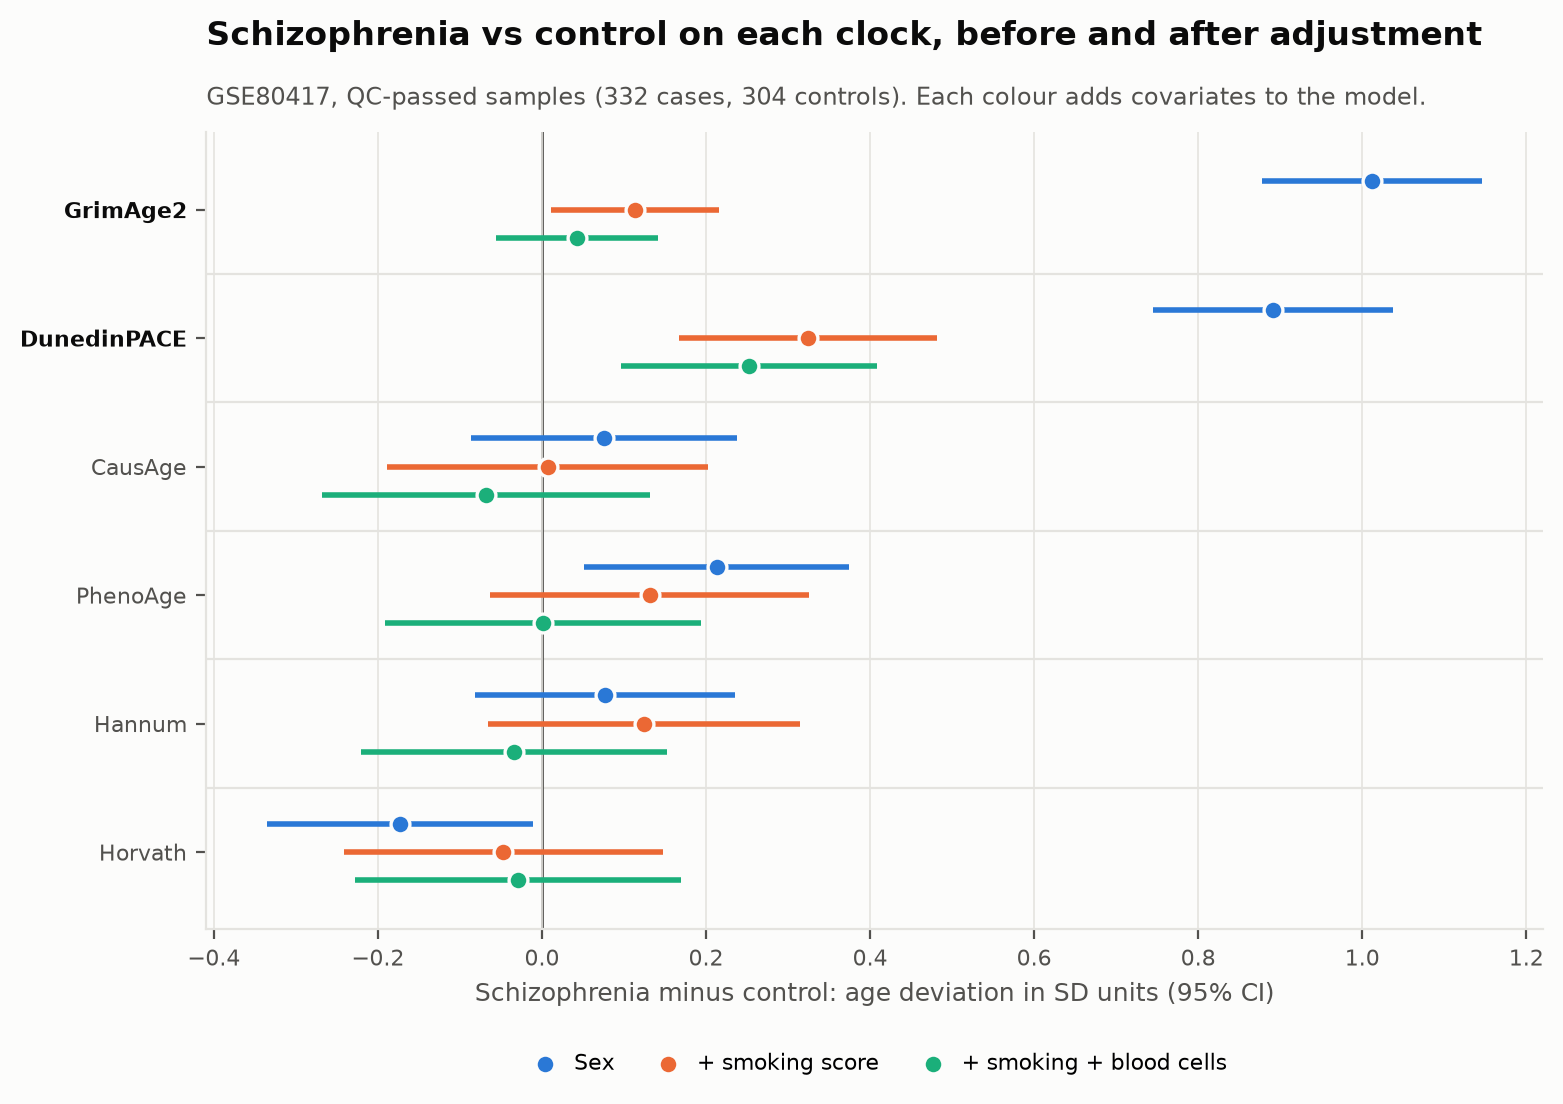

**GSE84727**

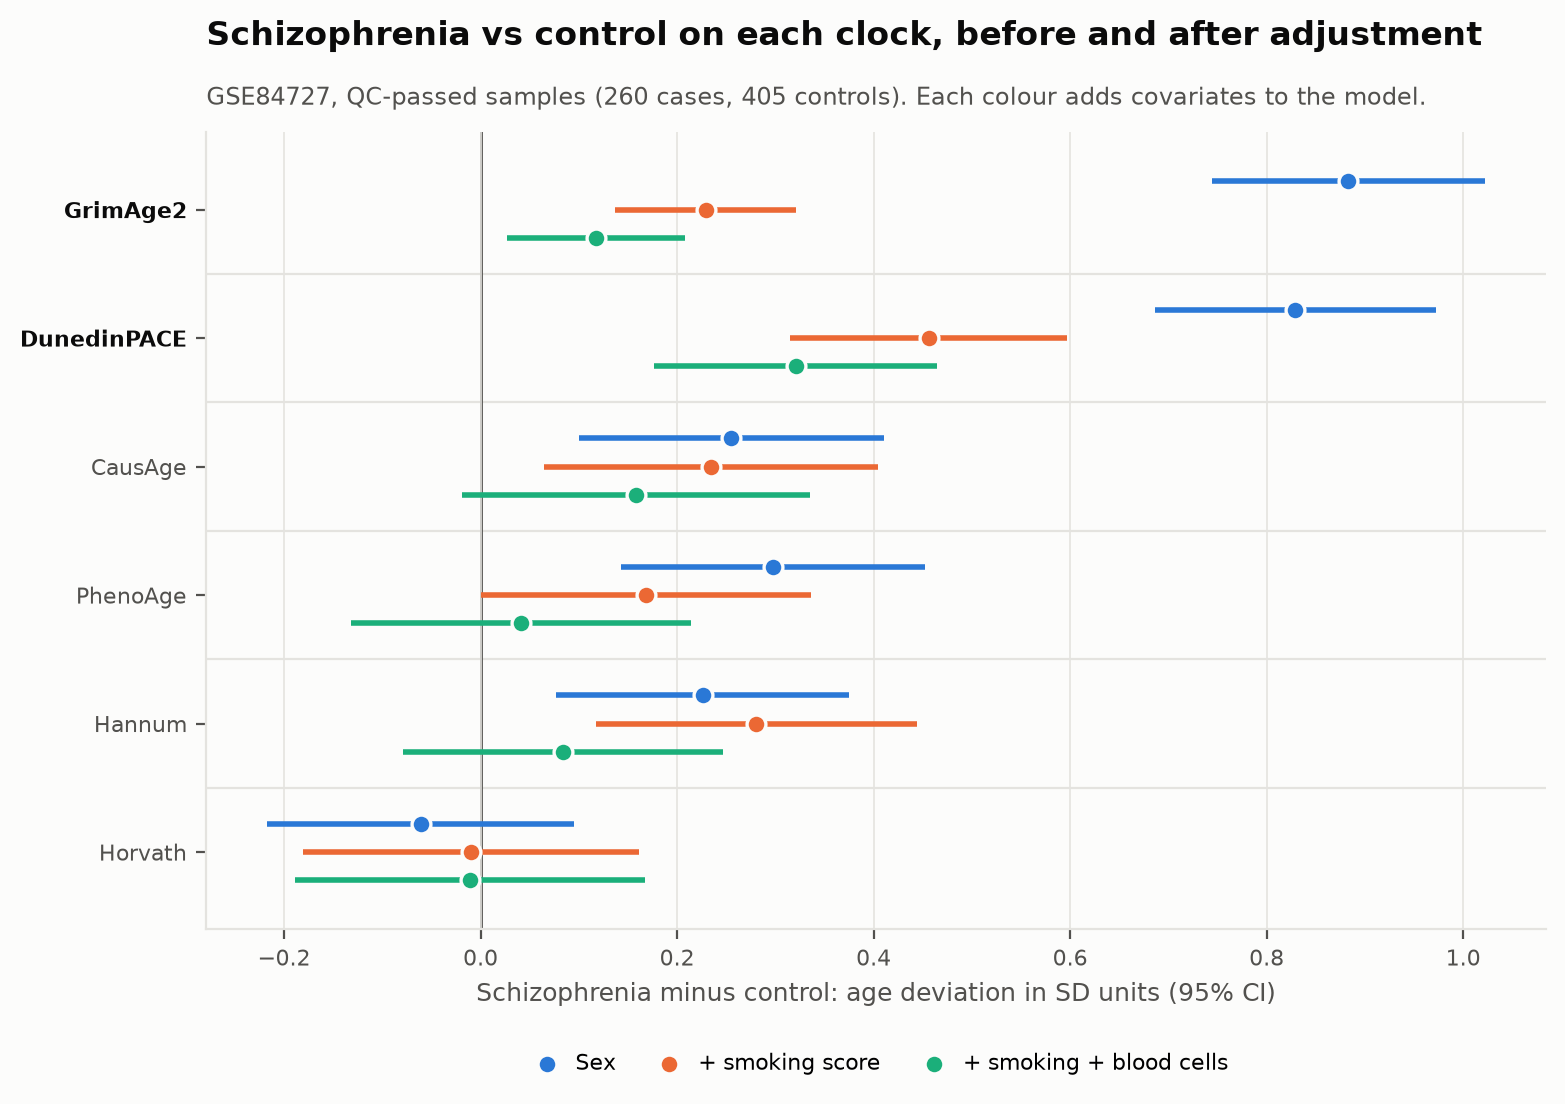

In [7]:
for g in COHORTS:
    display(Markdown(f"**{g}**"), Image(filename=R / g / "adjustment_effect.png", width=760))

## 4. Pooled across the three cohorts

Random-effects meta-analysis. `random` is the pooled estimate; `hk_ci_low` to `hk_ci_high` and `hk_p` are its Hartung–Knapp interval and p-value, the ones to quote with three studies. `random_p` (normal approximation) is shown for comparison only.

In [8]:
pooled = pd.read_csv(R / "pooled" / "pooled_effects.csv", index_col=[0, 1])
cols = ["k", "n_case", "n_control", "random", "hk_ci_low", "hk_ci_high", "hk_p", "random_p", "i2", "q_p"]
pooled.reindex(pd.MultiIndex.from_product([order, list(cfg.COVARIATE_MODELS)]))[cols].round(3)

k  n_case  n_control  random  hk_ci_low  hk_ci_high   hk_p  random_p     i2    q_p
GrimAge2    sex                3     653        740   4.824      2.749       6.900  0.010     0.000  0.761  0.015
            sex+smoking        3     653        740   0.448     -1.986       2.881  0.512     0.298  0.791  0.008
            sex+smoking+cells  3     653        740   0.268     -0.931       1.468  0.437     0.287  0.451  0.162
DunedinPACE sex                3     653        740   0.104      0.056       0.152  0.011     0.000  0.565  0.101
            sex+smoking        3     653        740   0.038     -0.030       0.105  0.138     0.004  0.709  0.032
            sex+smoking+cells  3     653        740   0.031     -0.008       0.069  0.077     0.000  0.361  0.209
CausAge     sex                3     653        740   0.312     -1.884       2.508  0.603     0.461  0.665  0.051
            sex+smoking        3     653        740   0.356     -1.137       1.848  0.413     0.321  0.421  0.178
            sex+smoking+cells  3     653        740   0.139     -1.185       1.463  0.695     0.674  0.313  0.233
PhenoAge    sex                3     653        740   1.205     -0.384       2.793  0.082     0.001  0.216  0.279
            sex+smoking        3     653        740   0.648     -0.906       2.202  0.215     0.067  0.081  0.337
            sex+smoking+cells  3     653        740   0.064     -0.621       0.749  0.727     0.847  0.000  0.794
Hannum      sex                3     653        740   0.353     -1.338       2.044  0.464     0.298  0.545  0.111
            sex+smoking        3     653        740   0.618     -0.845       2.080  0.211     0.051  0.355  0.212
            sex+smoking+cells  3     653        740   0.093     -0.687       0.873  0.659     0.670  0.000  0.502
Horvath     sex                3     653        740  -0.582     -1.836       0.673  0.184     0.047  0.308  0.236
            sex+smoking        3     653        740  -0.153     -0.815       0.510  0.426     0.545  0.000  0.689
            sex+smoking+cells  3     653        740  -0.120     -0.643       0.404  0.429     0.647  0.000  0.805

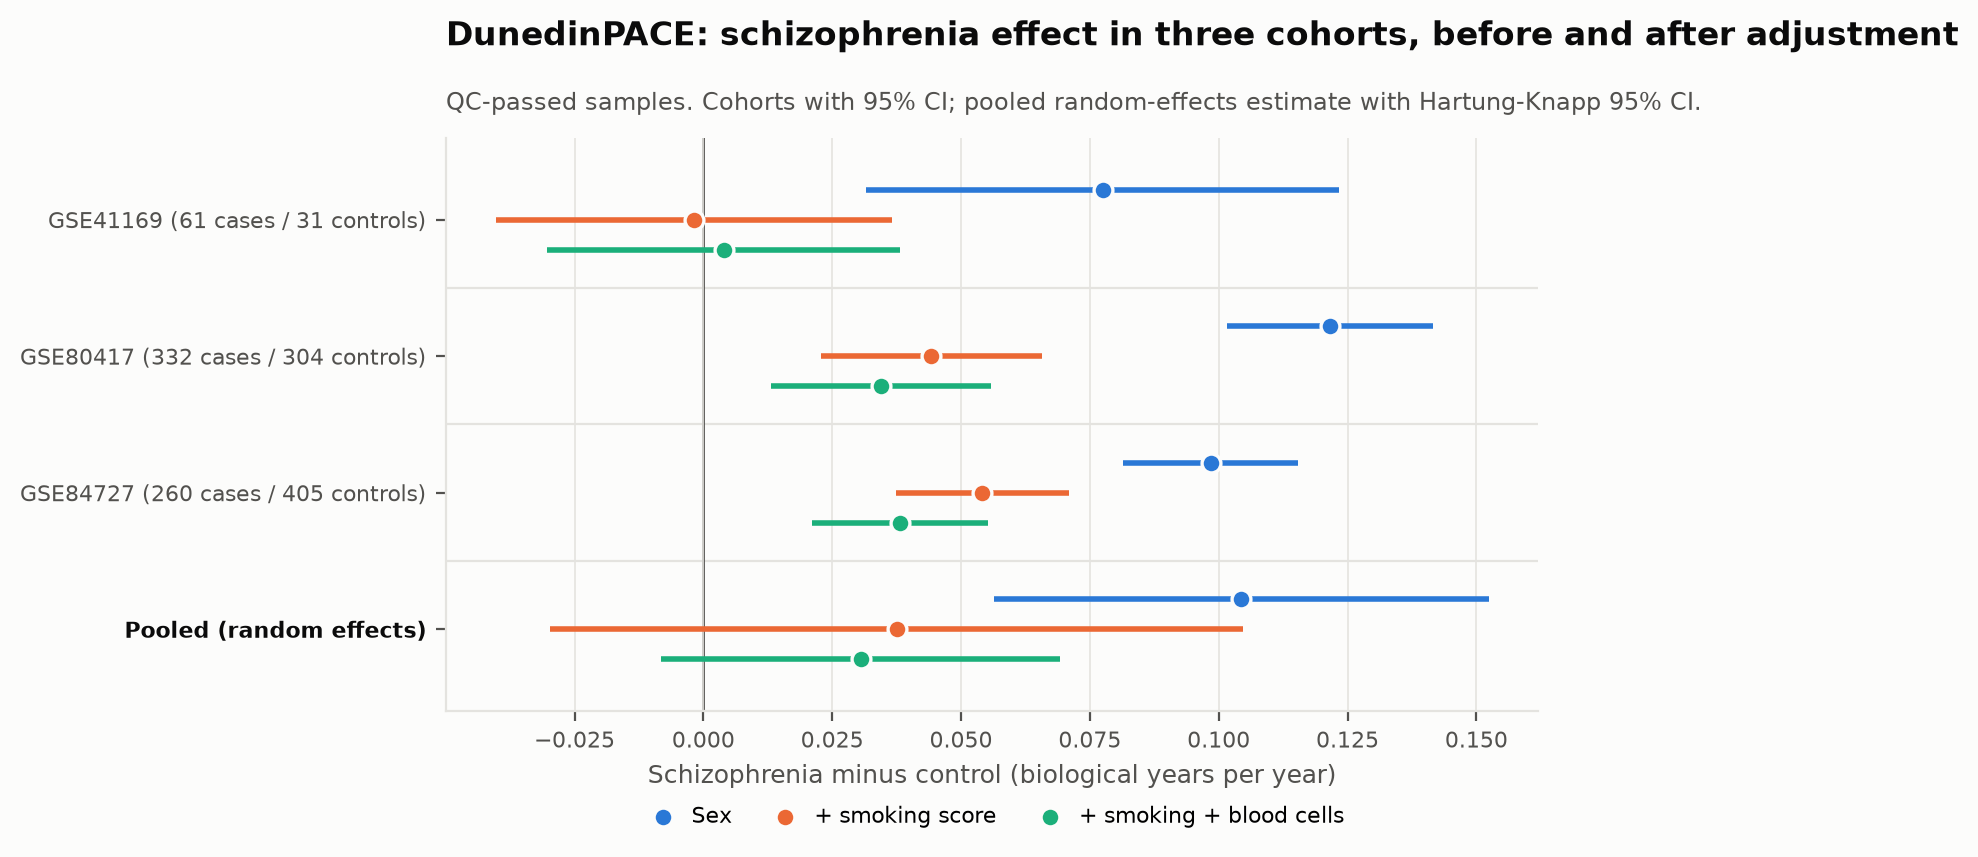

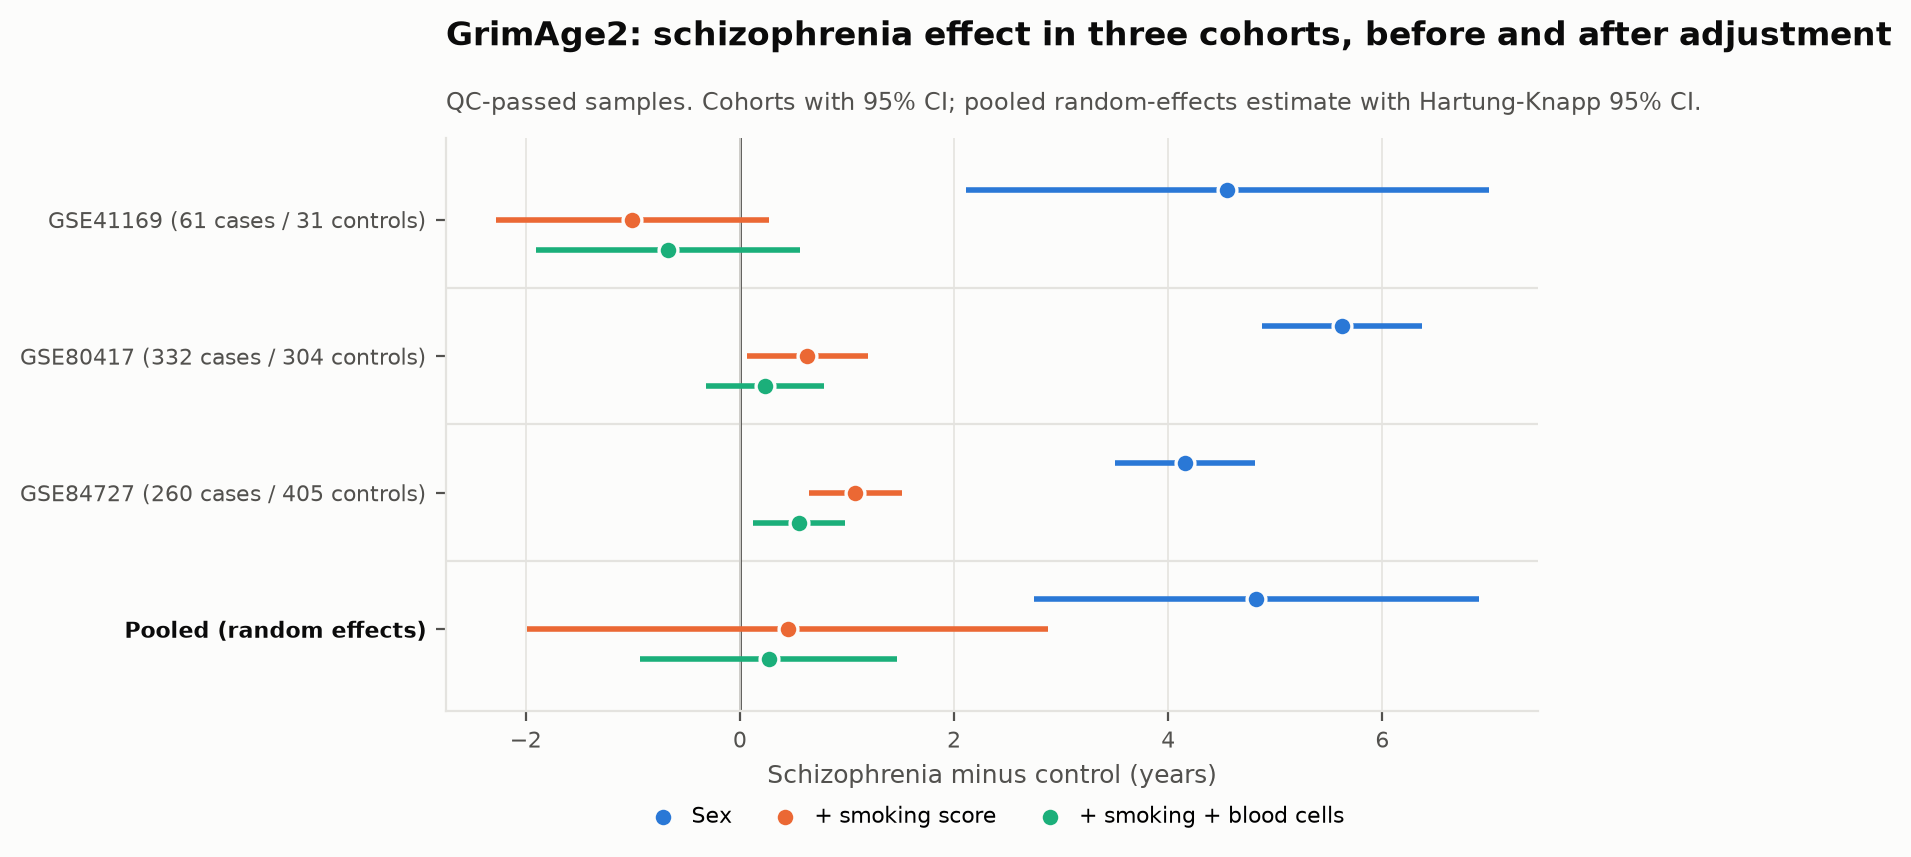

In [9]:
for clock in ["DunedinPACE", "GrimAge2"]:
    display(Image(filename=R / "pooled" / f"pooled_{clock}.png", width=820))

## 5. What GSE84727's missing probes do

GSE84727 was deposited without about 65,000 probes. The other two cohorts were rerun on its probe set: how well the estimates agree, and how the schizophrenia effect changes (in SD units of the all-probe age deviation, so shrinkage shows).

**GSE41169**

,"r, estimate","r, age deviation",mean shift,"SD ratio, age deviation"
GrimAge2,0.993,0.983,-1.381,0.811
DunedinPACE,0.976,0.967,-0.023,0.844
CausAge,0.996,0.974,1.814,0.982
PhenoAge,1.000,0.999,0.033,1.003
Hannum,0.999,0.991,0.915,0.875
Horvath,0.997,0.977,-0.613,0.980


all probes                                     GSE84727 probes only                                    
                      sex              sex+smoking                             sex              sex+smoking           
            diff_adjusted p_adjusted diff_adjusted p_adjusted        diff_adjusted p_adjusted diff_adjusted p_adjusted
clock                                                                                                                 
GrimAge2            0.759      0.000        -0.167      0.127                0.548      0.002        -0.185      0.060
DunedinPACE         0.697      0.001        -0.017      0.925                0.461      0.012        -0.025      0.886
CausAge            -0.300      0.166        -0.142      0.560               -0.322      0.127        -0.176      0.457
PhenoAge           -0.051      0.816        -0.202      0.416               -0.047      0.831        -0.185      0.456
Hannum             -0.259      0.243        -0.189      0.453               -0.256      0.186        -0.158      0.470
Horvath            -0.387      0.080        -0.230      0.352               -0.450      0.036        -0.277      0.246

**GSE80417**

,"r, estimate","r, age deviation",mean shift,"SD ratio, age deviation"
GrimAge2,0.996,0.984,-1.321,0.838
DunedinPACE,0.981,0.979,0.000,0.890
CausAge,0.996,0.967,-0.041,0.961
PhenoAge,1.000,0.998,-0.621,0.990
Hannum,0.999,0.991,0.427,0.950
Horvath,0.998,0.985,-0.589,0.983


all probes                                     GSE84727 probes only                                    
                      sex              sex+smoking                             sex              sex+smoking           
            diff_adjusted p_adjusted diff_adjusted p_adjusted        diff_adjusted p_adjusted diff_adjusted p_adjusted
clock                                                                                                                 
GrimAge2            1.012      0.000         0.113      0.030                0.818      0.000         0.111      0.023
DunedinPACE         0.891      0.000         0.324      0.000                0.741      0.000         0.376      0.000
CausAge             0.076      0.363         0.007      0.945                0.049      0.543        -0.026      0.787
PhenoAge            0.213      0.010         0.131      0.186                0.198      0.016         0.114      0.247
Hannum              0.077      0.343         0.124      0.201                0.085      0.269         0.137      0.139
Horvath            -0.173      0.037        -0.047      0.635               -0.144      0.077        -0.022      0.823

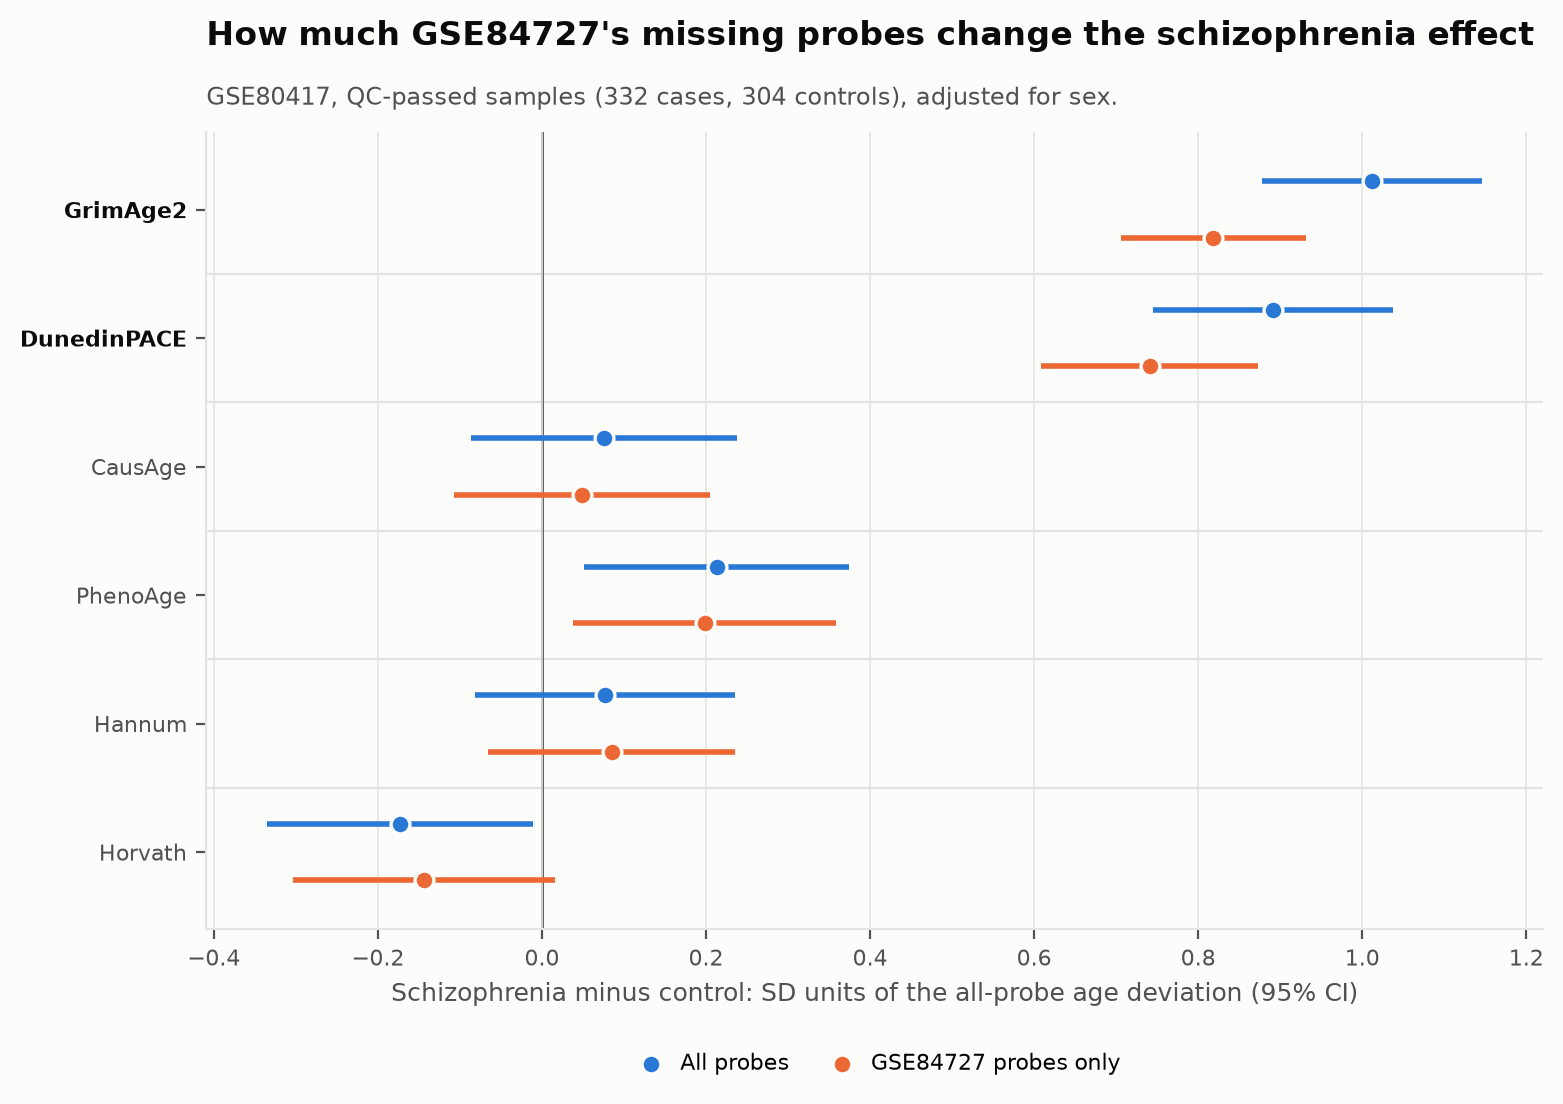

In [10]:
probes = cfg.SENSITIVITY_PROBES
for g in [c for c in COHORTS if c != probes]:
    display(Markdown(f"**{g}**"))
    display(pd.read_csv(R / g / f"probe_sensitivity_agreement_{probes}.csv", index_col=0).loc[order].round(3))
    display(pd.read_csv(R / g / f"probe_sensitivity_effects_{probes}.csv", index_col=0, header=[0, 1, 2]).loc[order].round(3))
display(Image(filename=R / "GSE80417" / f"probe_sensitivity_{probes}.png", width=760))